# PROYECTO DE ANALÍTICA DE DATOS - MACI 2026
**Alumnos:** 
1. Keyden Urbina P.
2. Christian Hardtmann.
3. Francisco Flores.

**Dataset:** Amazon Products Sales Dataset 2025

**Fuente:** https://www.kaggle.com/datasets/ikramshah512/amazon-products-sales-dataset-42k-items-2025?resource=download

### Cómo leer este notebook

Este notebook **explora** el dataset limpio: describe cada variable, cómo se distribuye y cómo se relacionan entre sí. **No modifica los datos**; solo los lee y guarda gráficos en `figuras/`.

- Requiere haber ejecutado antes `02. data_preprocessing_raw.ipynb`, que genera `data/procesado/amazon_electronics_cleaned_with_asin.csv`.
- `datos` es el dataset limpio (9.472 filas) y `productos` deja **una fila por producto** (la última captura de cada ASIN, 8.825 productos). Las distribuciones se miden sobre `productos`, para que un producto capturado varias veces no pese más que otro.

## Etapa 1: Exploración de los datos limpios

### Paso 1 -- Librerías, carpetas y carga de datos

**Qué hace:** carga las librerías, lee el CSV limpio y arma la tabla `productos` (una fila por producto). También define `distribucion`, una función que dibuja el histograma y el diagrama de caja de una variable numérica; se reutiliza en los pasos 6 a 9 para no repetir código.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

# Rutas del proyecto (funciona desde notebooks/ o desde la raíz)
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESADO, FIGURAS = BASE / "data" / "procesado", BASE / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

datos = pd.read_csv(PROCESADO / "amazon_electronics_cleaned_with_asin.csv", parse_dates=["delivery_date", "data_collected_at"])
productos = datos.sort_values("data_collected_at")                                # una fila por producto: su última captura
productos = productos[productos["asin"].isna() | ~productos.duplicated("asin", keep="last")]
NUM = ["discounted_price", "original_price", "discount_percentage", "product_rating", "total_reviews",
       "purchased_last_month", "n_capturas"]
print(f"{len(datos):,} filas | {len(productos):,} productos | capturas del "
      f"{datos['data_collected_at'].min():%d-%m} al {datos['data_collected_at'].max():%d-%m-%Y}")

def distribucion(s, nombre, num, log, nota="", bins=40):
    "Histograma + diagrama de caja (en gráficos separados). Con log=True, cuartiles y atípicos se miden en escala log."
    t = np.log10(s) if log else s
    q1, q3 = t.quantile([0.25, 0.75])
    inf, sup = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n_atip = ((t < inf) | (t > sup)).sum()
    q1, q3 = (10 ** q1, 10 ** q3) if log else (q1, q3)
    print(f"{nombre}: {len(s):,} productos | mediana {s.median():,.1f} | media {s.mean():,.1f} | "
          f"50% central entre {q1:,.1f} y {q3:,.1f} | atípicos: {n_atip:,} ({n_atip / len(s):.1%})")
    escala = " (escala log)" if log else ""

    fig, ax = plt.subplots(figsize=(8, 4))                                       # histograma + curva de densidad
    sns.histplot(s, log_scale=log, bins=bins, kde=True, color="#1f77b4", ax=ax)
    ax.axvline(s.median(), color="#e6550d", lw=1.5, label=f"mediana {s.median():,.1f}")
    ax.axvline(s.mean(), color="#2ca02c", lw=1.5, ls="--", label=f"media {s.mean():,.1f}")
    ax.set(xlabel=nombre + escala, ylabel="productos")
    ax.set_title(f"Distribución de productos por {nombre}{nota}", fontweight="bold", fontsize=10)
    ax.legend(fontsize=8, frameon=False)
    plt.tight_layout()
    plt.savefig(FIGURAS / f"{num}_{nombre.split()[0]}_distribucion.png", dpi=200)
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 2.8))                                     # diagrama de caja
    sns.boxplot(x=s, log_scale=log, color="#9ecae1", flierprops={"marker": "o", "markersize": 4, "alpha": 0.5}, ax=ax)
    ax.set(xlabel=f"{nombre}{escala}   (caja: Q1 {q1:,.1f} · mediana {s.median():,.1f} · Q3 {q3:,.1f})")
    ax.set_title(f"Diagrama de caja de {nombre}  ·  {n_atip:,} productos atípicos", fontweight="bold", fontsize=10)
    plt.tight_layout()
    plt.savefig(FIGURAS / f"{num + 1}_{nombre.split()[0]}_caja.png", dpi=200)
    plt.show()

9,472 filas | 8,825 productos | capturas del 21-08 al 30-08-2025


### Paso 2 -- Revisión estadística general

**Qué hace:**
1. Estadística descriptiva de las variables numéricas, con % de nulos, **asimetría** (sobre 1 indica una cola larga) y % de atípicos (regla IQR en escala normal).
2. Resumen de las variables categóricas: valores distintos, % de nulos y valor más frecuente.
3. **Controles de consistencia:** casos que no deberían existir. Todos deben dar 0.

In [2]:
q1, q3 = datos[NUM].quantile(0.25), datos[NUM].quantile(0.75)
fuera = (datos[NUM] < q1 - 1.5 * (q3 - q1)) | (datos[NUM] > q3 + 1.5 * (q3 - q1))
desc = datos[NUM].describe().T.assign(**{"% nulos": datos[NUM].isna().mean() * 100,
                                         "asimetría": datos[NUM].skew(), "% atípicos": fuera.mean() * 100})
display(desc.drop(columns="count").round(2))

CAT = ["product_category", "is_best_seller", "buy_box_availability", "sustainability_tags"]
display(pd.DataFrame({"valores distintos": datos[CAT].nunique(), "% nulos": datos[CAT].isna().mean() * 100,
                      "más frecuente": datos[CAT].mode().iloc[0],
                      "% del más frecuente": datos[CAT].apply(lambda s: s.value_counts(normalize=True).iloc[0] * 100)}).round(1))
print(f"Patrocinados: {datos['is_sponsored'].mean():.1%} | con cupón: {datos['has_coupon'].mean():.1%}\n")

controles = {
    "rating fuera de 1–5": ~datos["product_rating"].dropna().between(1, 5),
    "precio ≤ 0": datos["discounted_price"].le(0),
    "precio actual > precio de lista (descuento negativo)": datos["discount_percentage"].lt(0),
    "descuento > 100%": datos["discount_percentage"].gt(100),
    "entrega antes de la captura": datos["delivery_date"] < datos["data_collected_at"].dt.normalize(),
}
for nombre, falla in controles.items():
    print(f"{nombre:<55} {falla.sum():>6,} filas")

,mean,std,min,25%,50%,75%,max,% nulos,asimetría,% atípicos
discounted_price,202.85,401.28,2.16,27.01,77.21,196.29,5449.00,4.74,5.15,9.85
original_price,214.81,418.03,2.16,29.99,82.99,205.24,5449.00,4.74,5.18,10.07
discount_percentage,7.24,12.54,0.00,0.00,0.00,11.77,85.42,4.74,1.97,7.57
product_rating,4.44,0.30,1.00,4.30,4.50,4.60,5.00,0.72,-1.84,3.61
total_reviews,5942.50,23564.93,1.00,189.00,888.00,3650.25,865598.00,0.72,16.78,13.29
purchased_last_month,1448.87,5402.95,50.00,100.00,400.00,1000.00,100000.00,12.49,12.14,9.44
n_capturas,4.51,19.32,1.00,1.00,1.00,1.00,455.00,0.00,7.48,11.45


,valores distintos,% nulos,más frecuente,% del más frecuente
product_category,21,0.0,Other Electronics,10.0
is_best_seller,12,0.0,No Badge,94.0
buy_box_availability,1,36.1,Add to cart,100.0
sustainability_tags,16,91.3,Carbon impact,24.6


Patrocinados: 5.7% | con cupón: 2.3%

rating fuera de 1–5                                          0 filas
precio ≤ 0                                                   0 filas
precio actual > precio de lista (descuento negativo)         0 filas
descuento > 100%                                             0 filas
entrega antes de la captura                                  0 filas


**Lectura:** los 5 controles de consistencia dan 0. Precios, reseñas y compras son muy asimétricos (asimetría entre 5 y 17): la media queda muy por sobre la mediana, así que conviene describirlos con la mediana y modelarlos en logaritmo. Precio actual y precio de lista son casi la misma variable.

### Paso 3 -- Correlación entre variables

**Qué hace:** mide cuánto se mueven juntas dos variables con la **correlación de Spearman**, que compara posiciones (rankings) en vez de valores y por eso no se distorsiona con colas largas ni atípicos.
- **+1:** cuando una sube, la otra también · **−1:** cuando una sube, la otra baja · **0:** sin relación.
- Referencia: |valor| < 0,1 nula · 0,1–0,3 débil · 0,3–0,5 moderada · > 0,5 fuerte.
- La correlación solo acepta números, así que las columnas de texto y fecha se convierten a 1/0 o a días (solo dentro de esta celda). Se muestra solo la mitad de la matriz, porque la otra es un espejo.

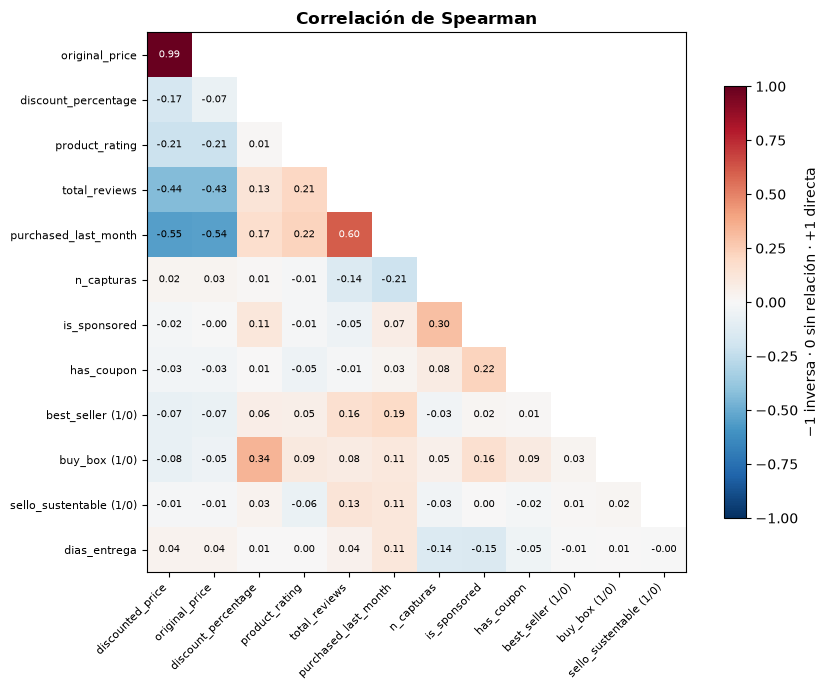

In [3]:
extra = pd.DataFrame({
    "best_seller (1/0)": datos["is_best_seller"].eq("Best Seller").astype(int),
    "buy_box (1/0)": datos["buy_box_availability"].notna().astype(int),
    "sello_sustentable (1/0)": datos["sustainability_tags"].notna().astype(int),
    "dias_entrega": (datos["delivery_date"] - datos["data_collected_at"].dt.normalize()).dt.days,
})
corr = pd.concat([datos[NUM + ["is_sponsored", "has_coupon"]], extra], axis=1).corr(method="spearman")
tri = corr.iloc[1:, :-1]                                               # sin diagonal (siempre 1) ni fila/columna vacías
tri = tri.where(~np.triu(np.ones(tri.shape, dtype=bool), k=1))          # solo la mitad inferior: la otra es un espejo

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(tri, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(tri.shape[1]), tri.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(tri.shape[0]), tri.index, fontsize=8)
for i, j in zip(*np.tril_indices(len(tri))):
    ax.text(j, i, f"{tri.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
            color="white" if abs(tri.iat[i, j]) > 0.6 else "black")
fig.colorbar(im, shrink=0.8, label="−1 inversa · 0 sin relación · +1 directa")
ax.set_title("Correlación de Spearman", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURAS / "15_correlaciones.png", dpi=200)
plt.show()

**Lectura:**

| Par | Valor | Lectura |
|---|---|---|
| Precio actual – precio de lista | 0,99 | Redundantes: en un modelo se usa uno de los dos más el % de descuento |
| Reseñas – compras del mes | 0,60 | Fuerte: lo que más se vende acumula más reseñas |
| Precio – compras del mes | −0,55 | Fuerte e inversa: lo más barato se compra más |
| Precio – reseñas | −0,44 | Moderada: los productos caros tienen menos reseñas |
| buy_box – % descuento | 0,34 | Moderada: los productos con botón de compra tienen más descuento |
| Patrocinado – n_capturas | 0,30 | Moderada: los anuncios eran los que más se repetían en la captura |
| Rating – resto | ≤ 0,22 | Débil: el rating casi no se relaciona con nada |

### Paso 4 -- Relación entre reseñas, compras y precio

**Qué hace:** un gráfico por par de variables.
- Compras del último mes viene en **tramos fijos** (50+, 100+, 1K+…), por eso se compara con **una caja por tramo**: la línea naranja es la mediana, escrita sobre cada caja.
- Precio y reseñas son continuas: se usa un **mapa de densidad** (hexágonos más oscuros = más productos) con la mediana de reseñas por decil de precio.

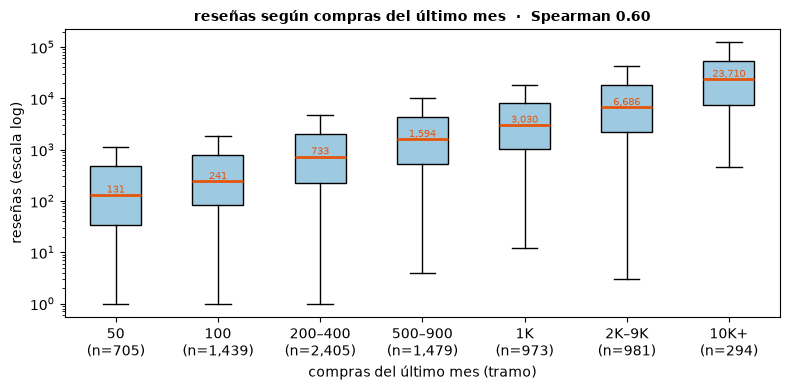

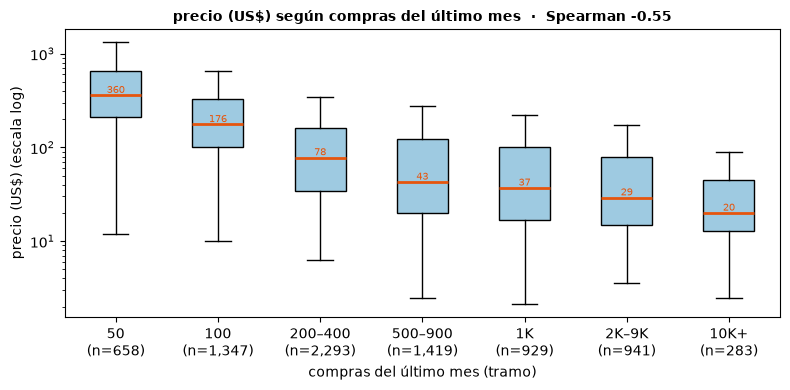

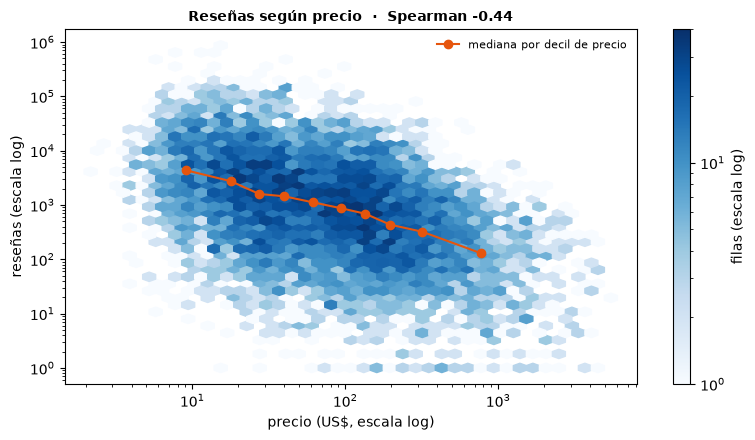

In [4]:
tramo = pd.cut(datos["purchased_last_month"], [0, 50, 100, 400, 900, 1_000, 9_999, np.inf],
               labels=["50", "100", "200–400", "500–900", "1K", "2K–9K", "10K+"])
rho = lambda a, b: datos[[a, b]].corr(method="spearman").iat[0, 1]

def cajas_por_tramo(col, nombre, archivo):
    grupos = [datos.loc[tramo == t, col].dropna() for t in tramo.cat.categories]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.boxplot(grupos, tick_labels=[f"{t}\n(n={len(g):,})" for t, g in zip(tramo.cat.categories, grupos)],
               showfliers=False, patch_artist=True, boxprops={"facecolor": "#9ecae1"}, medianprops={"color": "#e6550d", "lw": 2})
    for x, g in enumerate(grupos, start=1):                                       # mediana escrita sobre cada caja
        ax.text(x, g.median(), f"{g.median():,.0f}", ha="center", va="bottom", fontsize=7, color="#e6550d")
    ax.set(yscale="log", xlabel="compras del último mes (tramo)", ylabel=f"{nombre} (escala log)")
    ax.set_title(f"{nombre} según compras del último mes  ·  Spearman {rho(col, 'purchased_last_month'):.2f}",
                 fontweight="bold", fontsize=10)
    plt.tight_layout()
    plt.savefig(FIGURAS / archivo, dpi=200)
    plt.show()

cajas_por_tramo("total_reviews", "reseñas", "16_reseñas_vs_compras.png")            # GRÁFICO 16
cajas_por_tramo("discounted_price", "precio (US$)", "17_precio_vs_compras.png")      # GRÁFICO 17

# GRÁFICO 18: precio vs reseñas
par = datos[["discounted_price", "total_reviews"]].dropna()
fig, ax = plt.subplots(figsize=(8, 4.5))
hb = ax.hexbin(par["discounted_price"], par["total_reviews"], xscale="log", yscale="log", gridsize=40,
               bins="log", cmap="Blues", mincnt=1)
tendencia = par.groupby(pd.qcut(par["discounted_price"], 10), observed=True).median()
ax.plot(tendencia["discounted_price"], tendencia["total_reviews"], "o-", color="#e6550d", label="mediana por decil de precio")
fig.colorbar(hb, label="filas (escala log)")
ax.set(xlabel="precio (US$, escala log)", ylabel="reseñas (escala log)")
ax.set_title(f"Reseñas según precio  ·  Spearman {rho('discounted_price', 'total_reviews'):.2f}", fontweight="bold", fontsize=10)
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(FIGURAS / "18_precio_vs_reseñas.png", dpi=200)
plt.show()

**Lectura:**
1. **Reseñas vs. compras (Spearman 0,60):** la relación crece en cada tramo, sin excepciones. Los productos que venden más de 10.000 al mes tienen una mediana de reseñas 180 veces mayor que los que venden 50.
2. **Precio vs. compras (Spearman −0,55):** la relación es inversa y constante. Los productos más vendidos cuestan una mediana de US$ 20; los menos vendidos, US$ 360, es decir, 18 veces más.
3. **Precio vs. reseñas (Spearman −0,44):** la mediana de reseñas baja en cada decil de precio, de 4.341 en los productos de menos de US$ 13 a 129 en los de más de US$ 457. La nube es ancha, por eso la relación es moderada y no fuerte.

**Conclusión:** lo barato se vende más, y lo que se vende más acumula más reseñas. El precio probablemente influye en las reseñas a través del volumen de ventas, no de forma directa. Es una hipótesis: la correlación no prueba causa, pero orienta la selección de variables para el modelo.

### Paso 5 -- Distribución de productos por rating

**Qué hace:** histograma con curva de densidad y diagrama de caja del rating. Cada barra del histograma corresponde a un valor de rating (vienen en pasos de 0,1).

rating: 8,759 productos | mediana 4.5 | media 4.4 | 50% central entre 4.3 y 4.6 | atípicos: 319 (3.6%)


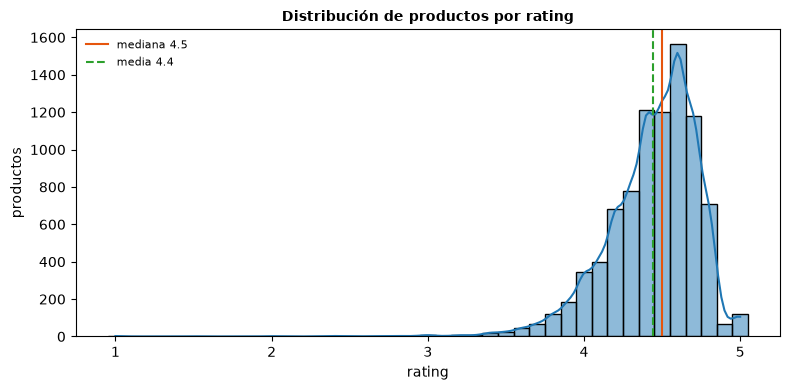

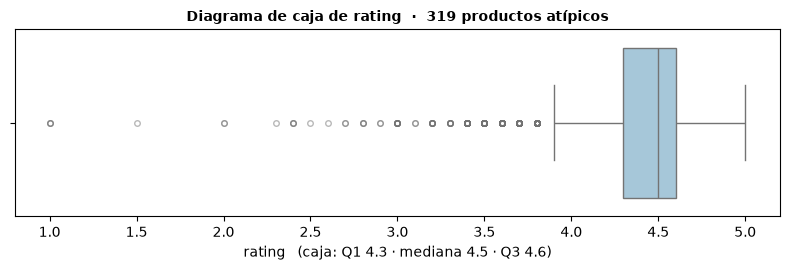

In [5]:
r = productos["product_rating"].dropna()
distribucion(r, "rating", 19, log=False, bins=np.arange(r.min() - 0.05, 5.1, 0.1))           # GRÁFICOS 19 y 20

**Lectura:** la mediana es 4,5 y la media 4,44; el valor más frecuente es 4,6. El 50% central está entre 4,3 y 4,6, un rango de apenas 0,3 puntos. Los 319 productos atípicos (3,6%) tienen rating bajo 3,85, y los peores llegan a 1,0.

**Qué implica:** casi todos los productos tienen rating alto y muy parecido, así que esta variable distingue poco entre productos; por eso su correlación con las demás es débil. Para un modelo puede servir más una versión binaria, por ejemplo "rating bajo" (< 3,85), que el valor continuo.

### Paso 6 -- Distribución de productos por número de reseñas

**Qué hace:** igual que el paso anterior, pero en **escala logarítmica**, porque las reseñas van de 1 a 865.598. Los cuartiles y los atípicos también se miden en escala log.

reseñas: 8,759 productos | mediana 898.0 | media 5,934.3 | 50% central entre 196.0 y 3,673.5 | atípicos: 85 (1.0%)


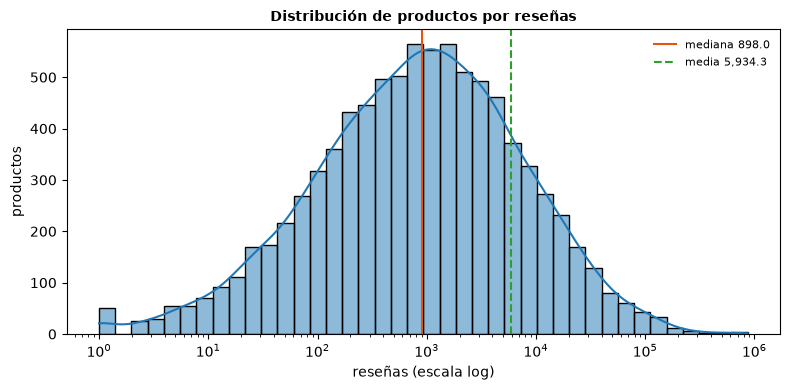

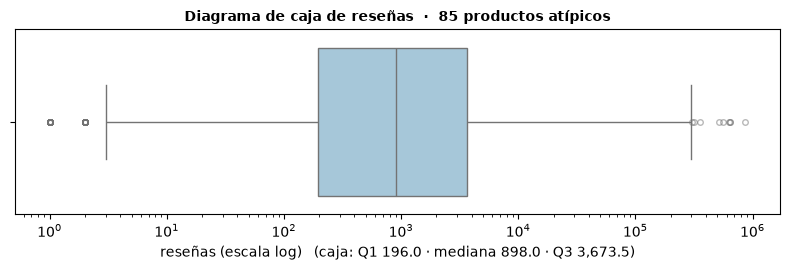

In [6]:
distribucion(productos["total_reviews"].dropna(), "reseñas", 21, log=True)                   # GRÁFICOS 21 y 22

**Lectura:** en escala log la distribución tiene forma de campana, con la mayoría de los productos entre 100 y 10.000 reseñas. La mediana es 898 y la media 5.934, casi 7 veces más, porque unos pocos productos con cientos de miles de reseñas la arrastran. El 50% central tiene entre 196 y 3.673 reseñas. Los 85 atípicos (1%) son 76 productos con 1 o 2 reseñas y 9 superventas con más de 298.000.

**Por qué aquí hay 85 atípicos y en el Paso 2 un 13%:** en el Paso 2 se calculan en escala normal, donde cualquier producto sobre unas 9.000 reseñas parece extremo. En escala log, la natural de esta variable, solo quedan los casos realmente extremos. Para un modelo conviene usar el logaritmo de las reseñas.

### Paso 7 -- Distribución de productos por compras del último mes

**Qué hace:** Amazon solo muestra **tramos** ("50+", "100+", "1K+"…), así que en vez de un histograma se usa **una barra por tramo** (en naranjo, el tramo de la mediana), más el diagrama de caja en escala log.

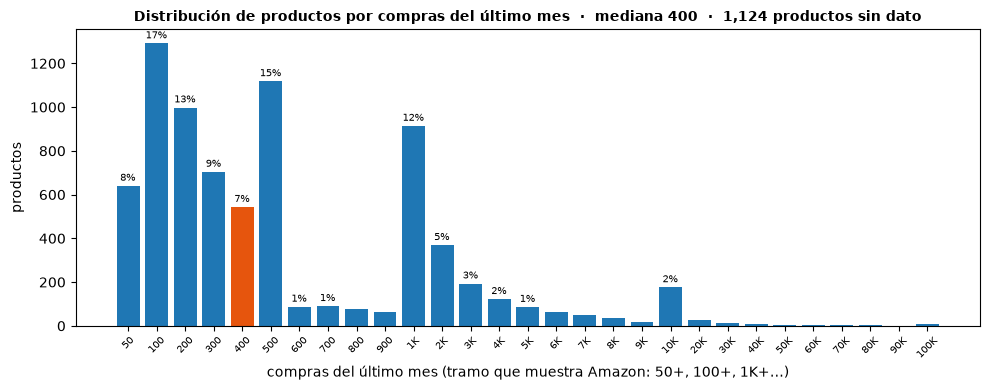

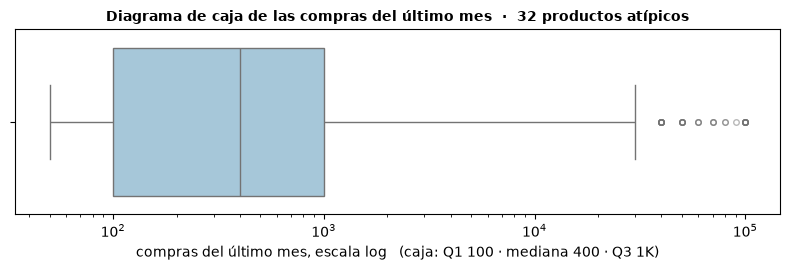

In [7]:
c = productos["purchased_last_month"].dropna()
etiqueta = lambda v: f"{v / 1000:g}K" if v >= 1000 else f"{v:g}"
conteo = c.value_counts().sort_index()

# GRÁFICO 23: productos por tramo de compras
fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.bar(conteo.index.map(etiqueta), conteo, color=["#e6550d" if v == c.median() else "#1f77b4" for v in conteo.index])
ax.bar_label(barras, labels=[f"{v / len(c):.0%}" if v / len(c) >= 0.01 else "" for v in conteo], fontsize=7, padding=2)
ax.set(xlabel="compras del último mes (tramo que muestra Amazon: 50+, 100+, 1K+…)", ylabel="productos")
ax.set_title(f"Distribución de productos por compras del último mes  ·  mediana {etiqueta(c.median())}  ·  "
             f"{productos['purchased_last_month'].isna().sum():,} productos sin dato", fontweight="bold", fontsize=10)
ax.tick_params(axis="x", labelsize=7, rotation=45)
plt.tight_layout()
plt.savefig(FIGURAS / "23_compras_distribucion.png", dpi=200)
plt.show()

# GRÁFICO 24: diagrama de caja en escala log
lq1, lq3 = np.log10(c).quantile([0.25, 0.75])
n_atip = (np.log10(c) > lq3 + 1.5 * (lq3 - lq1)).sum()
fig, ax = plt.subplots(figsize=(8, 2.8))
sns.boxplot(x=c, log_scale=True, color="#9ecae1", flierprops={"marker": "o", "markersize": 4, "alpha": 0.5}, ax=ax)
ax.set(xlabel=f"compras del último mes, escala log   (caja: Q1 {etiqueta(10 ** lq1)} · mediana {etiqueta(c.median())} · Q3 {etiqueta(10 ** lq3)})")
ax.set_title(f"Diagrama de caja de las compras del último mes  ·  {n_atip:,} productos atípicos", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.savefig(FIGURAS / "24_compras_caja.png", dpi=200)
plt.show()

**Lectura:** la mediana es 400. Los tramos más frecuentes son 100+ (17%), 500+ (15%), 200+ (13%) y 1K+ (12%), que juntos concentran el 57% de los productos. El 50% central vende entre 100 y 1.000 al mes, y los 32 atípicos (0,4%) venden entre 40K y 100K. La media (1.375) es más de 3 veces la mediana. El 12,7% de los productos no tiene dato.

Hay picos en 500+, 1K+ y 10K+, y los tramos intermedios (600–900, 6K–9K) casi no tienen productos: probablemente Amazon redondea hacia abajo a cifras "redondas", así que un "500+" puede ser cualquier valor entre 500 y 999.

**Qué implica:** esta variable conviene tratarla como categoría ordenada o en logaritmo, no como número exacto, y hay que decidir cómo tratar el 12,7% sin dato (excluirlo o marcarlo como "sin información").

### Paso 8 -- Distribución de productos por precio y por % de descuento

**Qué hace:** histograma y diagrama de caja de cada variable.
- El precio va en escala log (de US$ 2 a US$ 5.449). Se usa solo el precio actual: el de lista es prácticamente igual (correlación 0,99).
- El descuento se grafica solo para los productos **con** descuento; el % sin descuento queda anotado en el título.

precio (US$): 8,398 productos | mediana 79.0 | media 206.3 | 50% central entre 27.7 y 199.0 | atípicos: 11 (0.1%)


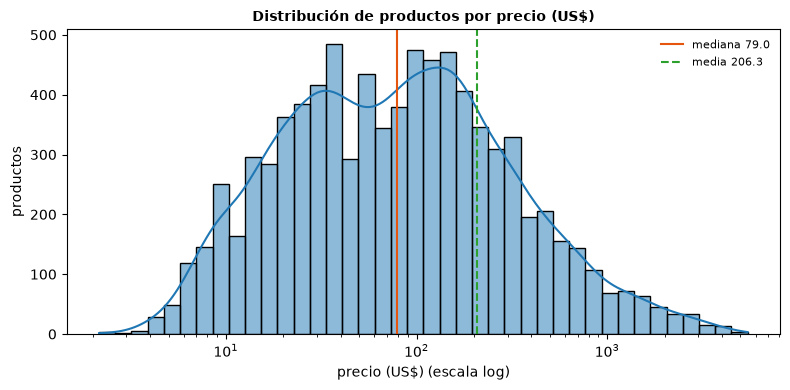

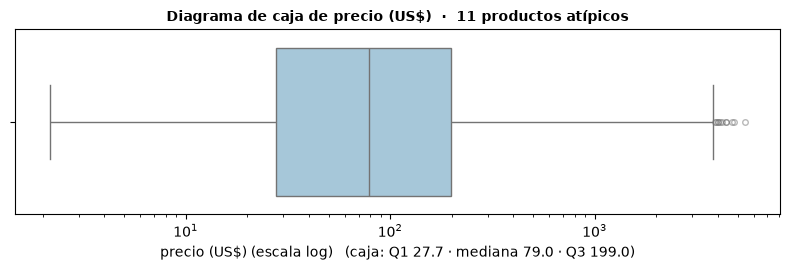

descuento (%): 2,769 productos | mediana 18.7 | media 21.1 | 50% central entre 11.1 y 28.5 | atípicos: 49 (1.8%)


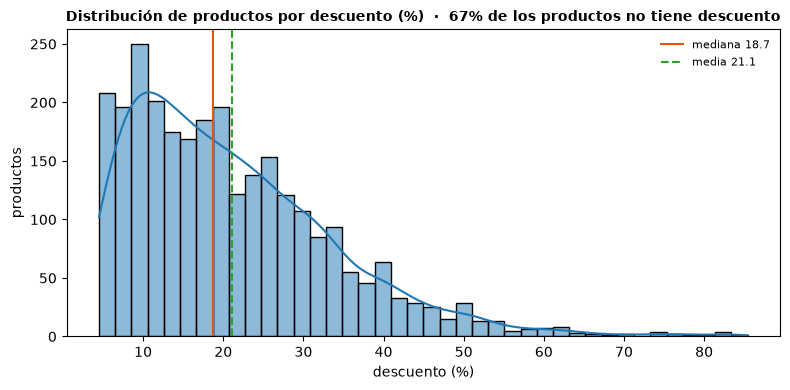

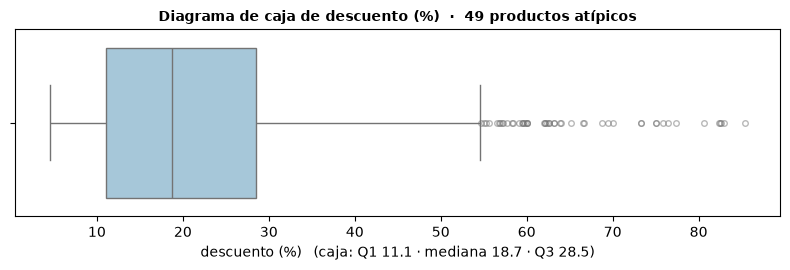

In [8]:
distribucion(productos["discounted_price"].dropna(), "precio (US$)", 25, log=True)          # GRÁFICOS 25 y 26
d = productos["discount_percentage"].dropna()
distribucion(d[d > 0], "descuento (%)", 27, log=False,                                         # GRÁFICOS 27 y 28
             nota=f"  ·  {(d == 0).mean():.0%} de los productos no tiene descuento")

**Lectura:**
- **Precio:** en escala log tiene forma de campana. La mediana es US$ 79 y la media US$ 206, casi 3 veces más, por unos pocos productos caros. El 50% central está entre US$ 27,7 y US$ 199. Medidos en escala log, solo 11 productos son atípicos.
- **Descuento:** dos de cada tres productos no tienen descuento. Entre los que sí tienen, la mediana es 18,7% y lo típico está entre 11% y 29%. Los descuentos sobre 50% son raros, con un máximo de 85%.

**Qué implica:** el descuento funciona mejor como dos variables: **¿tiene descuento?** (1/0), que separa al 67% sin descuento, y **¿cuánto?**, que solo tiene sentido para el 33% restante.

### Paso 9 -- Distribución de productos por variable categórica

**Qué hace:** para las variables categóricas no aplican histograma ni caja: se cuenta cuántos productos hay en cada valor. Un gráfico por variable; los vacíos aparecen como "Sin dato" (gris) y las variables 1/0 como "No" / "Sí".

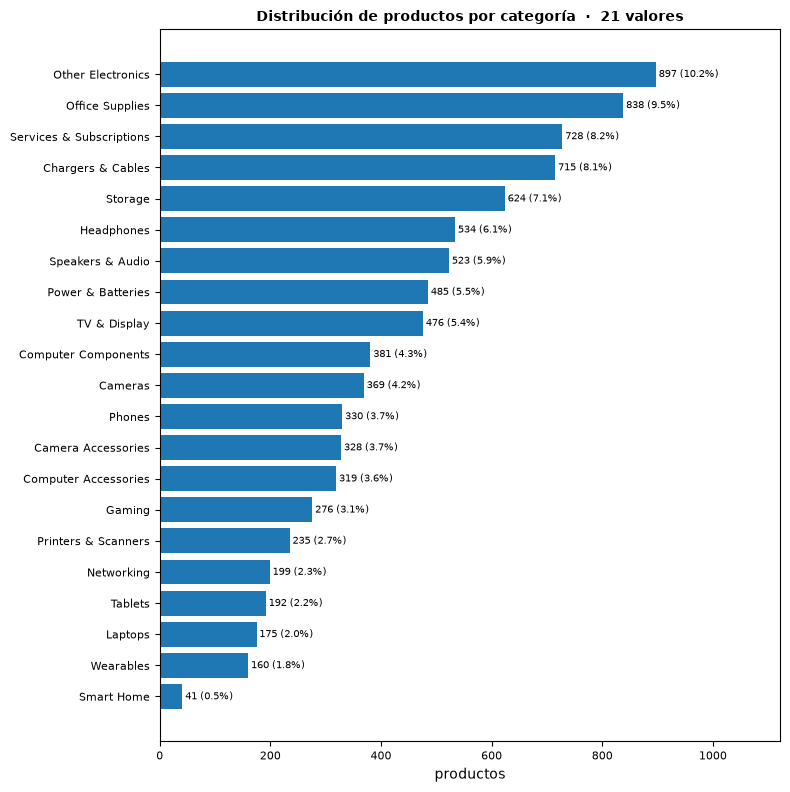

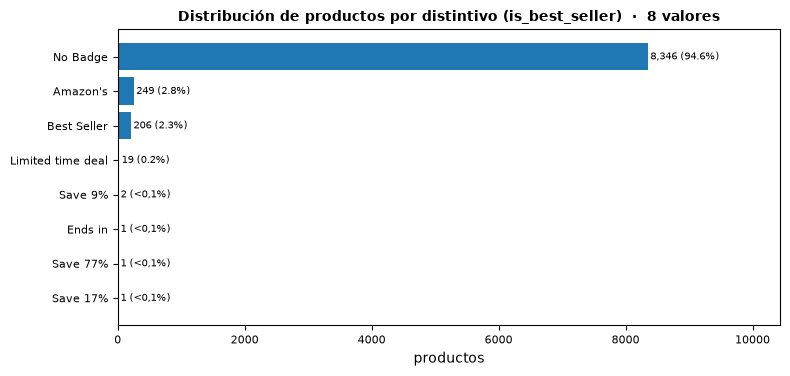

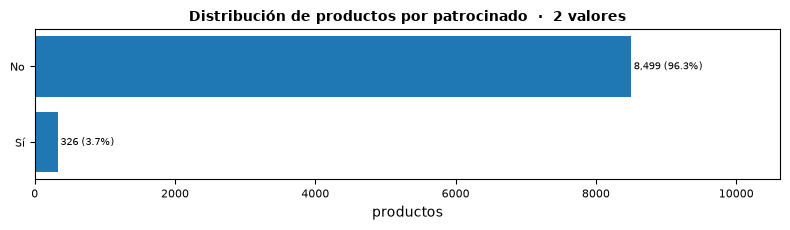

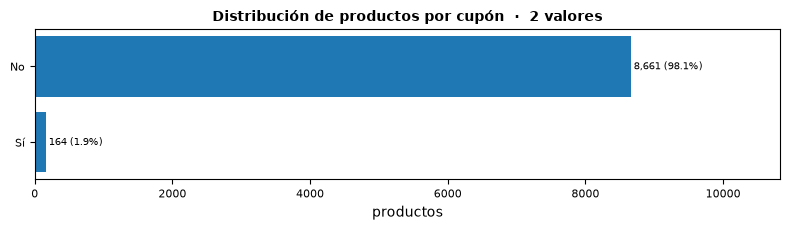

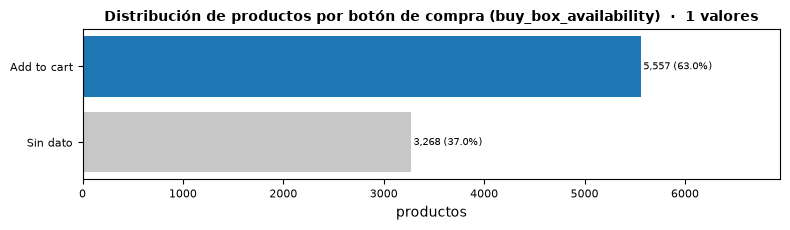

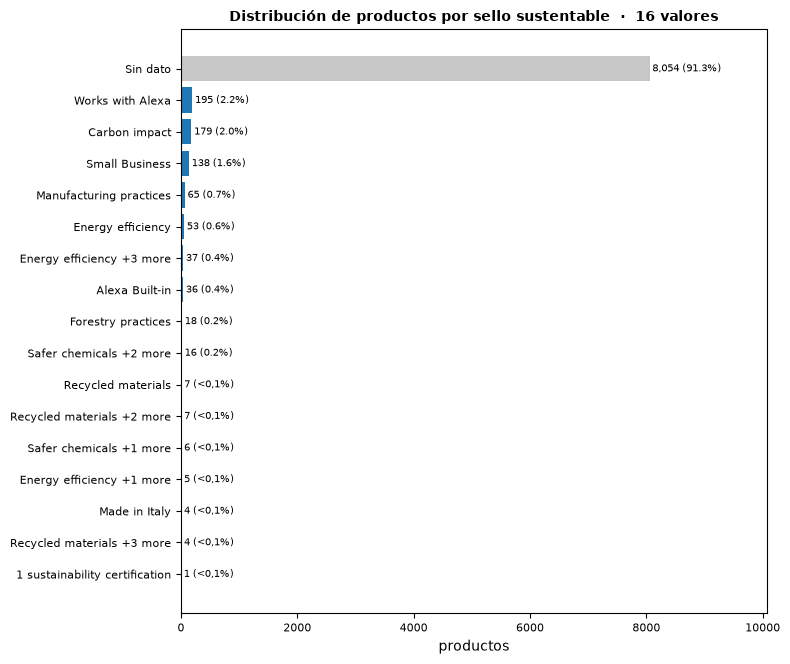

In [9]:
CATEGORICAS = {"product_category": "categoría", "is_best_seller": "distintivo (is_best_seller)",
               "is_sponsored": "patrocinado", "has_coupon": "cupón",
               "buy_box_availability": "botón de compra (buy_box_availability)", "sustainability_tags": "sello sustentable"}

for num, (col, nombre) in enumerate(CATEGORICAS.items(), start=29):                         # GRÁFICOS 29 a 34
    s = productos[col].replace({0: "No", 1: "Sí"}) if productos[col].dtype.kind == "i" else productos[col]
    conteo = s.fillna("Sin dato").value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(8, max(2.4, 0.32 * len(conteo) + 1.3)))
    barras = ax.barh(conteo.index.astype(str), conteo, color=["#c7c7c7" if k == "Sin dato" else "#1f77b4" for k in conteo.index])
    ax.bar_label(barras, labels=[f"{n:,} ({n / len(s):.1%})" if n / len(s) >= 0.001 else f"{n:,} (<0,1%)" for n in conteo],
                 fontsize=7, padding=2)
    ax.set(xlim=(0, conteo.max() * 1.25), xlabel="productos")
    ax.set_title(f"Distribución de productos por {nombre}  ·  {s.nunique()} valores", fontweight="bold", fontsize=10)
    ax.tick_params(labelsize=8)
    plt.tight_layout()
    plt.savefig(FIGURAS / f"{num}_{col}_distribucion.png", dpi=200)
    plt.show()

**Lectura:**

| Variable | Resultado | Qué implica |
|---|---|---|
| Categoría | 21 categorías; la mayor es Other Electronics (10,2%) | Bastante repartida: ninguna domina |
| Distintivo | No Badge 94,6% · Amazon's 2,8% · **Best Seller 2,3%** (206 productos) | Para predecir "Best Seller" hay 1 caso positivo por cada 42 negativos: problema desbalanceado (balanceo de clases, métricas F1 o AUC) |
| Patrocinado | Sí 3,7% | Era 16,4% de las filas con capturas repetidas: los anuncios estaban sobrerrepresentados |
| Cupón | Sí 1,9% | Muy poca variación: aportará poco |
| Botón de compra | Add to cart 63% · sin dato 37% | En la práctica es una variable sí/no |
| Sello sustentable | Sin dato 91,3% | Datos escasos; valores como "Energy efficiency +3 more" indican que el scraper capturó solo el primer sello |

## Etapa 2: Preguntas exploratorias de investigación

### Paso 10 -- Formulación de la pregunta de investigación

**Pregunta:** ¿Permiten las reseñas (`total_reviews`), el precio (`original_price`) y la puntuación (`product_rating`) identificar los productos con alta demanda (`purchased_last_month` ≥ 400)?


### Paso 11 -- Formulación de Hipótesis:
| | Enunciado |
|---|---|
| **H₀** | El precio y la puntuación no mejoran la identificación de productos de alta demanda respecto de usar solo las reseñas |
| **H₁** | El precio y la puntuación sí mejoran la identificación de productos de alta demanda respecto de usar solo las reseñas |


## Conclusiones de la exploración

1. **Los datos limpios son consistentes:** ningún rating fuera de 1–5, precio negativo, descuento imposible ni entrega anterior a la captura.
2. **Precio, reseñas y compras tienen colas largas:** se describen con la mediana y conviene modelarlos en logaritmo.
3. **Relaciones principales:** lo barato se vende más (precio vs. compras −0,55) y lo que se vende más acumula reseñas (0,60).
4. **Variables con poca información:** el rating varía poco (50% entre 4,3 y 4,6); cupón (1,9%) y sello sustentable (91% sin dato) aportan poco.